# PPO CNN RGB từ model xám: setup, train, vẽ, test (chạy một mạch bằng Run All)

Quy trình:
1. Lấy CNN xám `pen_const_low_s0`, mở rộng lớp conv đầu 4 -> 12 kênh (đầu ra ban đầu gần như giữ nguyên) rồi train tiếp với `rgb_scale=True`.
2. Train theo **từng đoạn** `CHUNK` bước. Sau mỗi đoạn: lưu model + log + episodes, ghi tiến độ. Bị ngắt (tắt máy, tắt VS Code, kernel chết) thì chỉ mất tối đa một đoạn,
   chạy lại notebook sẽ tiếp từ đoạn đang dở.
3. Hết ngân sách giờ `MAX_HOURS` thì không bắt đầu đoạn mới, notebook đi tiếp sang vẽ và test.
4. Vẽ đường học, chấm điểm 20 ván (seed cố định, so với model nguồn xám và CNN RGB train từ đầu), và đo hành vi quanh ma xanh / ma thường.

Lưu ý: mỗi đoạn dùng một lịch lr riêng (giảm tuyến tính về 0 trong đoạn đó), nên lr có dạng răng cưa giữa các đoạn.

## 0. Setup

In [2]:
import json, time
from pathlib import Path
import numpy as np
import torch
from pacman_rl import PPOConfig, train_ppo, get_device, random_baseline
from pacman_rl.runs import save_run, load_run, load_model
from pacman_rl.plotting import compare
from pacman_rl.evaluation import ppo_policy, evaluate
from pacman_rl.envs import make_env
from pacman_rl.models.convert import load_gray_as_rgb

device = get_device()
print(device)

cuda


## 1. Tham số

In [ ]:
SMOKE = False                  # True: chạy thử vài update để kiểm notebook, không tốn thời gian
SEED = 0
RUN_DIR = "runs"
SRC = "pen_const_low_s0"       # CNN xám nguồn (death_penalty 2.5, 1M bước)
SCRATCH_RGB = "rgb_pen_const_low_s0"   # CNN RGB train từ đầu 1M bước, chỉ để so sánh
SP = 2                     # step_penalty
LR = 1e-4                      # thấp hơn lúc train đầu (2.5e-4) để không phá trọng số đã học
CHUNK = 1_000_000 if SMOKE else 10_000_000        # số bước mỗi đoạn (lưu sau mỗi đoạn)
N_CHUNKS = 2 if SMOKE else 10                 # tổng = N_CHUNKS * CHUNK (mặc định 10M bước)
MAX_HOURS = 8                  # sau ngần này giờ thì không bắt đầu đoạn mới

# death_penalty theo từng đoạn. Reward học là thang log: ăn con ma đầu ~3.0, nên 2.5 còn nhẹ hơn thưởng ăn ma.
# 3 đoạn đầu giữ 2.5 cho mạng kịp học màu, rồi tăng dần. Muốn một mức cố định thì viết [2.5] * N_CHUNKS.
DP_SCHEDULE = [2.5, 2.5, 2.5, 5, 5, 5, 10, 10, 10, 10]
if SMOKE: DP_SCHEDULE = [2.5, 5]
assert len(DP_SCHEDULE) == N_CHUNKS

DST = ("smoke_1" if SMOKE else "") + f"cnn_rgb_ramp_from_gray_s{SEED}"
PROGRESS = Path(RUN_DIR) / f"{DST}_progress.json"
CKPT = Path(RUN_DIR) / "ckpt" / f"{DST}.pt"      # checkpoint giữa đoạn, tách riêng để {DST}.pt luôn khớp với log
print(f"{DST}: {N_CHUNKS} đoạn x {CHUNK:,} bước = {N_CHUNKS * CHUNK:,} bước | dp {DP_SCHEDULE}")

cnn_rgb_ramp_from_gray_s0: 10 đoạn x 1,000,000 bước = 10,000,000 bước | dp [2.5, 2.5, 2.5, 5, 5, 5, 10, 10, 10, 10]


## 2. Train (theo đoạn, tự tiếp tục nếu bị ngắt)

In [5]:
def chunks_done():
    return json.loads(PROGRESS.read_text())["chunks_done"] if PROGRESS.exists() else 0

def make_cfg(dp):
    return PPOConfig(
        arch="cnn", lr=LR, total_steps=CHUNK, seed=SEED, rgb_scale=True,
        death_penalty=dp, step_penalty=SP,
        n_envs=4 if SMOKE else 32,
        n_steps=128 if SMOKE else 512,
        n_minibatches=4,
        save_every=2 if SMOKE else 10,       # đếm theo UPDATE (1 update = 16384 bước)
        log_every=1 if SMOKE else 10)

t_start = time.time()
for k in range(chunks_done(), N_CHUNKS):
    if (time.time() - t_start) / 3600 > MAX_HOURS:
        print(f"hết ngân sách {MAX_HOURS}h, dừng trước đoạn {k + 1}/{N_CHUNKS}")
        break
    if k == 0:
        model = load_gray_as_rgb(f"{RUN_DIR}/{SRC}.pt", "ppo", device).train()   # xám -> RGB
    else:
        model = load_run(RUN_DIR, DST, "ppo", device).model.train()              # tiếp từ đoạn trước
    dp = DP_SCHEDULE[k]
    print(f"=== đoạn {k + 1}/{N_CHUNKS} | dp {dp} | {CHUNK:,} bước | đã chạy {(time.time() - t_start) / 3600:.2f}h ===")
    result = train_ppo(cfg=make_cfg(dp), model=model, save_path=str(CKPT), device=device)
    save_run(result, RUN_DIR, DST, append=(k > 0))          # đoạn 0: ghi mới; các đoạn sau: nối log
    PROGRESS.write_text(json.dumps({"chunks_done": k + 1}))
print(f"xong {chunks_done()}/{N_CHUNKS} đoạn, tổng {(time.time() - t_start) / 3600:.2f}h")

=== đoạn 3/10 | dp 2.5 | 1,000,000 bước | đã chạy 0.00h ===
PPO: 61 updates x 16384 mẫu = 999,424 bước, 32 env song song
Update 10/61 | step 163,840 | avg score(20) 563 | 769 lượt | 213 bước/lượt | 0.36 viên NL/lượt | 0.22 ma/lượt | phạt chết 2.5 bước 2.000 | entropy 1.109 | KL -0.0000 | clipfrac 0.091 | 2014 steps/s
Update 20/61 | step 327,680 | avg score(20) 650 | 780 lượt | 210 bước/lượt | 0.36 viên NL/lượt | 0.25 ma/lượt | phạt chết 2.5 bước 2.000 | entropy 1.161 | KL 0.0040 | clipfrac 0.167 | 2044 steps/s
Update 30/61 | step 491,520 | avg score(20) 628 | 763 lượt | 215 bước/lượt | 0.37 viên NL/lượt | 0.22 ma/lượt | phạt chết 2.5 bước 2.000 | entropy 1.228 | KL 0.0057 | clipfrac 0.234 | 2128 steps/s
Update 40/61 | step 655,360 | avg score(20) 513 | 783 lượt | 209 bước/lượt | 0.37 viên NL/lượt | 0.20 ma/lượt | phạt chết 2.5 bước 2.000 | entropy 1.290 | KL 0.0015 | clipfrac 0.069 | 2164 steps/s
Update 50/61 | step 819,200 | avg score(20) 548 | 743 lượt | 221 bước/lượt | 0.39 viên NL/

c:\Users\LENOVO\miniconda3\envs\rel_pacman\lib\site-packages\gymnasium\vector\async_vector_env.py:460: UserWarning: WARN: Calling `close` while waiting for a pending call to `step` to complete.
  logger.warn(


xong 10/10 đoạn, tổng 0.92h


## 3. Vẽ đường học

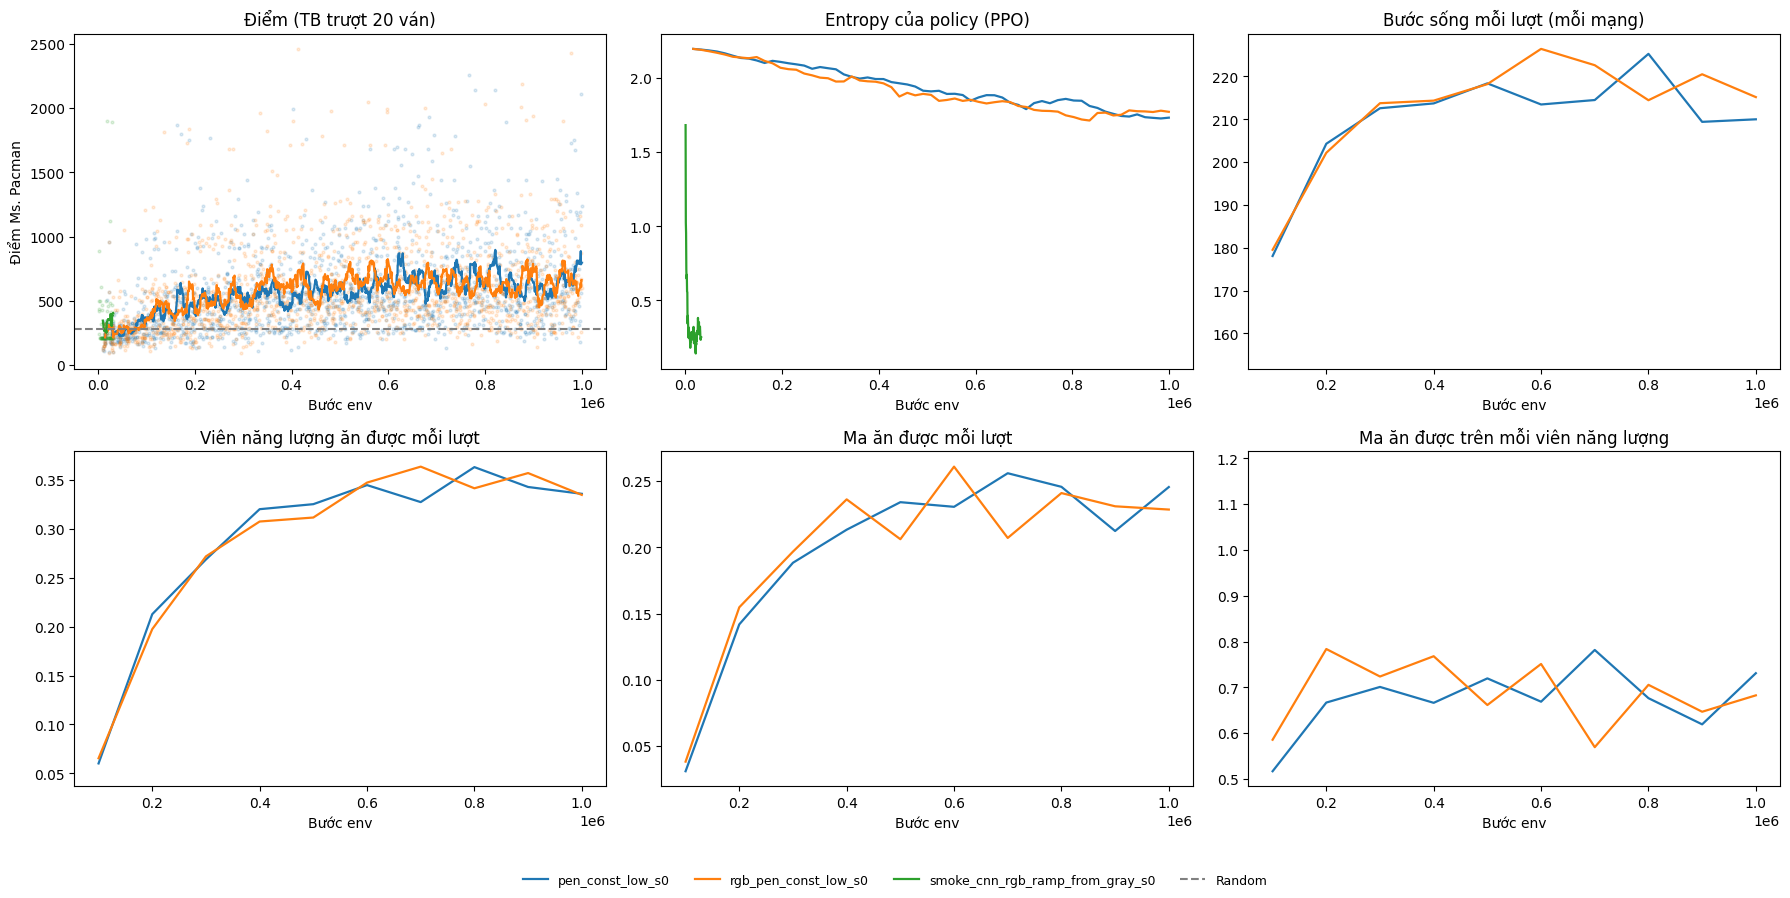

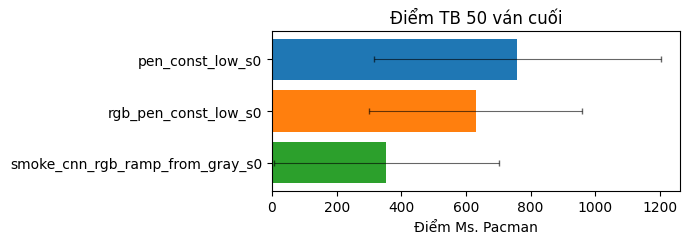

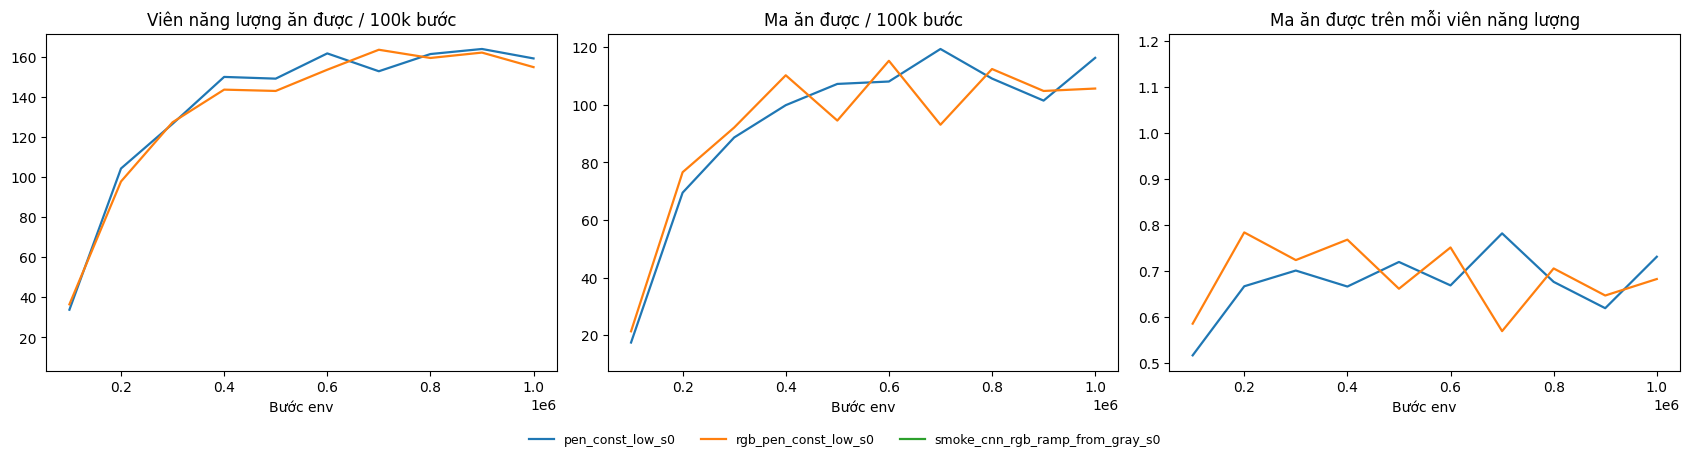

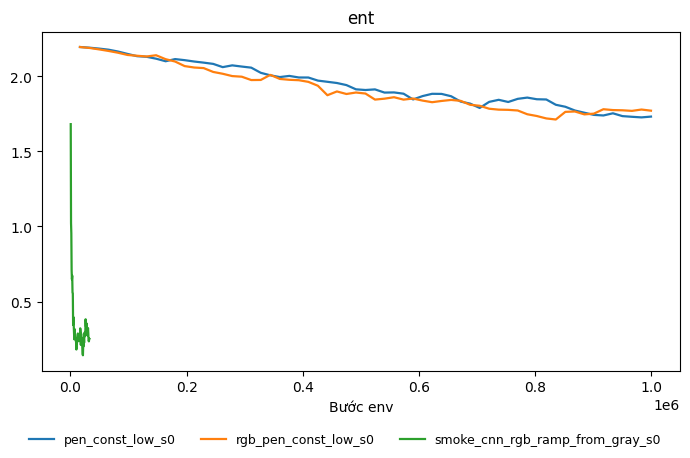

In [5]:
names = [SRC, SCRATCH_RGB, DST]
runs = compare(names=names, directory=RUN_DIR, random_scores=random_baseline(5),
               metrics=("ent",), device=device, save_path=f"{RUN_DIR}/{DST}_compare.png")

## 4. Chấm điểm (seed cố định, cùng ván cho mọi model)
Điểm là điểm game thật, nên so được giữa các run.

In [1]:
N_EVAL = 3 if SMOKE else 20
rows = {}
for n in names:
    model = load_run(RUN_DIR, n, "ppo", device).model.to(device).eval()
    rows[n] = evaluate(ppo_policy(model, device), n_episodes=N_EVAL, seed=1000)
    print(f"{n:40s} TB {np.mean(rows[n]):7.0f} | std {np.std(rows[n]):6.0f} | max {np.max(rows[n]):6.0f}")
json.dump({n: [float(x) for x in v] for n, v in rows.items()}, open(f"{RUN_DIR}/{DST}_eval.json", "w"))

NameError: name 'SMOKE' is not defined

## 5. Hành vi quanh ma xanh / ma thường
Pha "ma ăn được" = `W` bước agent sau khi ăn viên năng lượng (reward 50 hoặc 60), pha còn lại = "ma nguy hiểm". Khoảng cách tới con ma gần nhất lấy từ RAM ALE
(byte 6..9 / 12..15 là x / y của ma, byte 10 / 16 là x / y của Pacman, theo bảng AtariARI, **chưa được kiểm lại** với Ms. Pacman). `W` cũng là ước lượng.
Cột "đổi TB" âm nghĩa là agent đang lao tới ma, dương là đang rời xa. Nếu mạng phân biệt được màu thì hai pha phải khác nhau (lao tới ở pha ma xanh, né ở pha ma thường).

In [7]:
def ghost_diag(model, n_ep=8, W=80, NEAR=40, seed=1000):
    model = model.to(device).eval()
    act = ppo_policy(model, device)
    env = make_env(rgb_scale=model.in_channels == 12)
    ale = env.unwrapped.ale
    def nearest():
        ram = ale.getRAM(); px, py = int(ram[10]), int(ram[16])
        return min(abs(int(ram[6 + i]) - px) + abs(int(ram[12 + i]) - py) for i in range(4))
    st = {k: dict(steps=0, close=0, delta=[], deaths=0, eaten=0) for k in ("ma ăn được", "ma nguy hiểm")}
    scores = []
    try:
        for ep in range(n_ep):
            obs, _ = env.reset(seed=seed + ep); act.reset()
            t_pp, lives, done, sc, steps = -10**9, ale.lives(), False, 0.0, 0
            d_prev = nearest()
            while not done and steps < 4500:
                ph = "ma ăn được" if steps - t_pp < W else "ma nguy hiểm"
                obs, r, te, tr, _ = env.step(act(np.asarray(obs)))
                steps += 1; sc += r; done = te or tr
                s = st[ph]; s["steps"] += 1
                d = nearest()
                if d_prev < NEAR: s["close"] += 1; s["delta"].append(d - d_prev)
                d_prev = d
                if r in (50, 60): t_pp = steps
                if ph == "ma ăn được" and r in (200, 400, 800, 1600, 210, 410, 810, 1610): s["eaten"] += 1
                l = ale.lives()
                if l < lives: s["deaths"] += 1
                lives = l
            scores.append(sc)
    finally:
        env.close()
    return scores, st

N_DIAG = 2 if SMOKE else 8
for n in [SRC, DST]:
    model = load_run(RUN_DIR, n, "ppo", device).model
    scores, st = ghost_diag(model, N_DIAG)
    print(f"\n== {n} | {N_DIAG} ván, điểm TB {np.mean(scores):.0f} ==")
    for k, s in st.items():
        dl = np.array(s["delta"]) if s["delta"] else np.array([np.nan])
        print(f"{k:13s}: {s['steps']:6d} bước | gần ma: {s['close']:5d} | đổi TB {np.nanmean(dl):+.2f}/bước | chết {s['deaths']:2d} | ăn ma {s['eaten']:2d}")


== pen_const_low_s0 | 2 ván, điểm TB 490 ==
ma ăn được   :    160 bước | gần ma:     0 | đổi TB +nan/bước | chết  0 | ăn ma  0
ma nguy hiểm :   1207 bước | gần ma:   619 | đổi TB +0.11/bước | chết  6 | ăn ma  0


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_6220\863856666.py:41: RuntimeWarning: Mean of empty slice
  print(f"{k:13s}: {s['steps']:6d} bước | gần ma: {s['close']:5d} | đổi TB {np.nanmean(dl):+.2f}/bước | chết {s['deaths']:2d} | ăn ma {s['eaten']:2d}")



== smoke_cnn_rgb_ramp_from_gray_s0 | 2 ván, điểm TB 275 ==
ma ăn được   :      0 bước | gần ma:     0 | đổi TB +nan/bước | chết  0 | ăn ma  0
ma nguy hiểm :    755 bước | gần ma:   561 | đổi TB +0.07/bước | chết  6 | ăn ma  0


## 6. Xem model vừa train chơi (cần màn hình)

In [8]:
from pacman_rl.evaluation import watch
watch(ppo_policy(load_run(RUN_DIR, DST, "ppo", device).model.to(device).eval(), device, greedy=True), episodes=1)

[play] ván 1: 210 điểm (373 bước)


[210.0]